# ANALYSE DES DONNÉES

## 1. Importation des bibliothèques

In [1]:
import numpy as np

import pandas as pd

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf

import matplotlib.pyplot as plt

import seaborn as sns
plt.style.use("dark_background")

## 2. Importation et aperçu du jeu de données

In [2]:
data=pd.read_excel("Data//donnee_debit_trait.xlsx")
data.head()

,Date,Valeur
0,1992-01-01,17.280001
1,1992-01-02,17.280001
2,1992-01-03,17.150000
3,1992-01-04,17.000000
4,1992-01-05,16.889999


### 2.1 Informations générales sur le jeu de données

Notre jeu de données contient 11688 observations et 2 colonnes : Date et Valeur, qui représente le débit.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11688 entries, 0 to 11687
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    11688 non-null  datetime64[us]
 1   Valeur  11688 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 182.8 KB


### 2.2 Statistiques descriptives

On voit que les valeurs minimale et maximale du débit sont respectivement de 0.6 et 1064. La moyenne (199.24) étant très éloignée de la médiane (28.7), cela confirme la présence de valeurs extrêmes, autrement dit la présence d'événements rares.

In [4]:
data.describe()

,Date,Valeur
count,11688,11688.000000
mean,2007-12-31 12:00:00,199.247091
min,1992-01-01 00:00:00,0.607000
25%,1999-12-31 18:00:00,9.368500
50%,2007-12-31 12:00:00,28.719999
75%,2015-12-31 06:00:00,286.899994
max,2023-12-31 00:00:00,1064.000000
std,NaN,293.009078


### 2.3 Analyse de la distribution

On voit une distribution asymétrique à droite (la moyenne très supérieure à la médiane confirme cette asymétrie). La majorité des observations se concentre sur des valeurs d'alerte normale, tandis qu'une proportion plus faible d'observations présente des valeurs d'alerte modérée et élevée. La densité présente également une concentration secondaire dans la zone des valeurs d'alerte extrême, de 1992 à 2023. Ce qui confirme bien l'importance de la réalisation de ce projet.

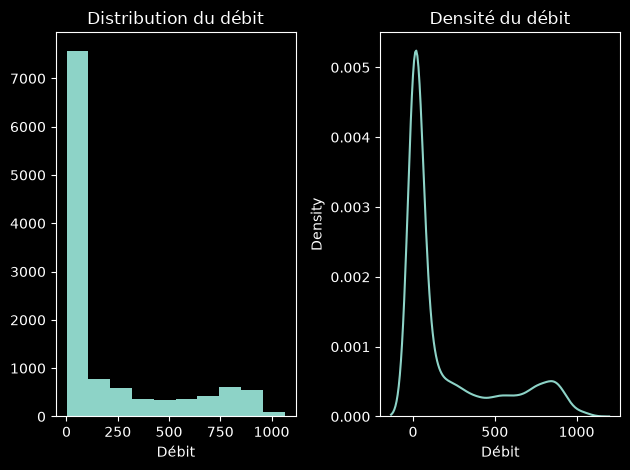

In [5]:
fig, axes=plt.subplots(2,2)

axes=axes.flat
axes[0].hist(data.Valeur)
axes[0].set_xlabel("Débit")
axes[0].set_title("Distribution du débit")
sns.kdeplot(data.Valeur,ax=axes[1])
axes[1].set_xlabel("Débit")
axes[1].set_title("Densité du débit")

axes[2].hist(data.Valeur)
axes[2].set_xlabel("Débit")
axes[2].set_title("Distribution du débit")
sns.kdeplot(data.Valeur,ax=axes[3])
axes[3].set_xlabel("Débit")
axes[3].set_title("Densité du débit")
plt.tight_layout()

## 3. Débit moyen par année et par mois

Cette heatmap nous montre que les mois d'août, septembre et octobre constituent les mois à surveiller pour un risque élevé et extrême. Le modèle choisi doit donc être capable de surveiller particulièrement ces mois. Les autres mois ne présentent quant à eux que peu de risque. On peut donc envisager d'entraîner notre modèle sur *les données de ces trois mois seulement*.

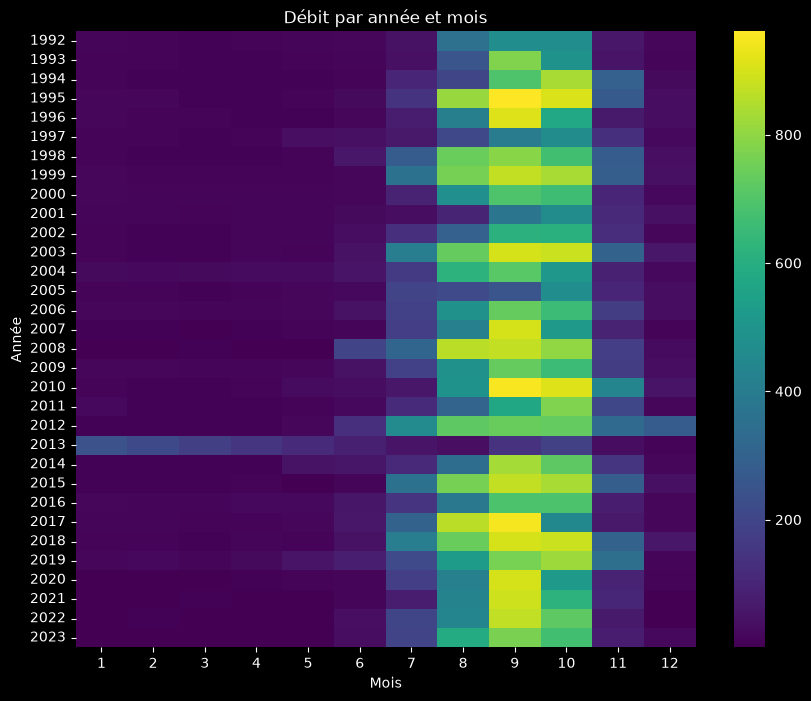

In [6]:
df = data.copy()
df["Annee"] = df["Date"].dt.year
df["Mois"] = df["Date"].dt.month
pivot =df.pivot_table(values="Valeur",index="Annee",columns="Mois",aggfunc="mean")
plt.figure(figsize=(10, 8))
sns.heatmap(pivot, cmap="viridis")
plt.title("Débit par année et mois")
plt.xlabel("Mois")
plt.ylabel("Année")
plt.show()

## 4. Analyse des valeurs extrêmes

### 4.1 Boxplot global du débit

C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_9940\4173246420.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data,y="Valeur",palette="Set2")


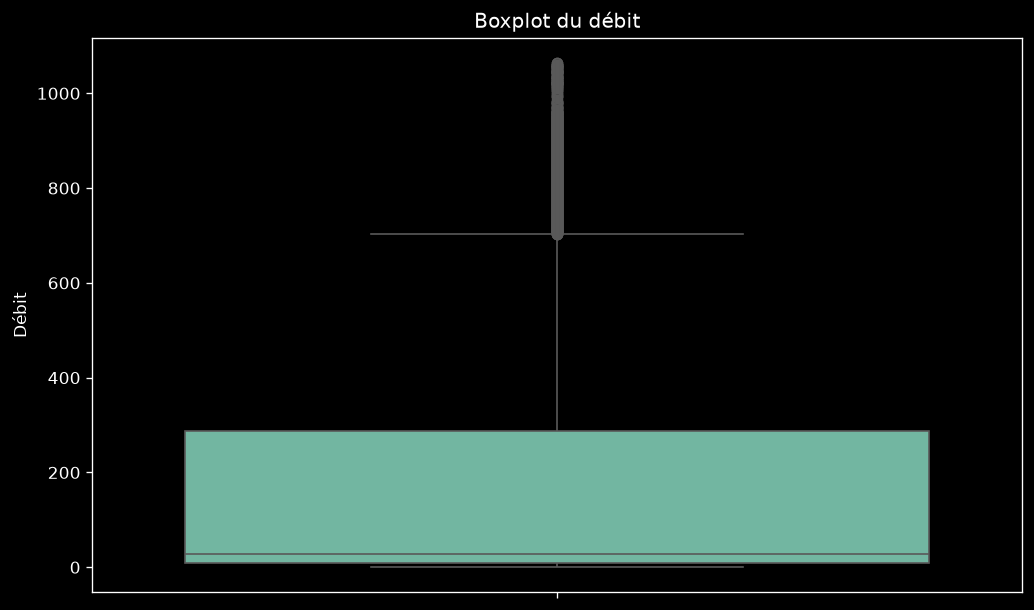

In [7]:
plt.figure(figsize=(10,6),dpi=120)
sns.boxplot(data,y="Valeur",palette="Set2")
plt.title("Boxplot du débit")
plt.ylabel("Débit");

### 4.2 Boxplot du débit par mois

Ce boxplot par mois confirme à nouveau l'importance des mois d'août, septembre et octobre dans cette prédiction. Le mois de septembre est particulier, car les valeurs faibles de débit y apparaissent très rarement : sur la période 1992-2023, le débit y est généralement élevé et il est très rare qu'il soit bas. C'est donc un mois à surveiller par avance par la population, sans oublier les mois d'août et d'octobre.

C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_9940\1765580141.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data,x=data.Date.dt.month,y="Valeur",palette="Set2")


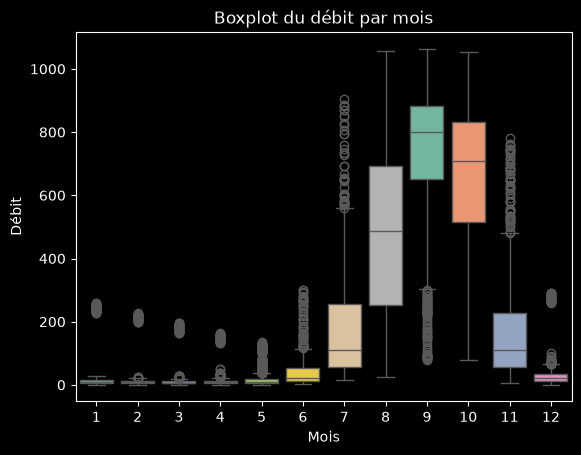

In [8]:
fid,axes=plt.subplots(1,2)
sns.boxplot(data,x=data.Date.dt.month,y="Valeur",palette="Set2",ax=axes[0])
sns.boxplot(data,x=data.Date.dt.month,y="Valeur",palette="Set2",ax=axes[1])

axes[0].set_title("Boxplot du débit par mois")
axes[1].set_title("Boxplot du pluie par mois")
plt.xlabel("Mois")
plt.ylabel("Débit")
plt.show()


## 5. Évolution mensuelle du débit par année

On voit que les années ne suivent pas toutes la même distribution, certaines années étant particulières. Parmi ces années, il y en a une qui rejette notre hypothèse d'entraîner et de prédire uniquement sur les mois d'août, septembre et octobre. Ce graphe montre donc qu'il est nécessaire de tenir compte de toutes les mois. Il est toutefois peu probable qu'un modèle tenant compte de la saisonnalité (comme SARIMA) fonctionne bien — ce n'est qu'une hypothèse.

La question qui se pose donc est : existe-t-il une relation, en termes de corrélation, entre le débit d'aujourd'hui et celui d'un éventuel jour n précédent ? Si oui, quelles sont les n optimal, les meilleurs ? Ce sera l'objectif du graphe qui va suivre.

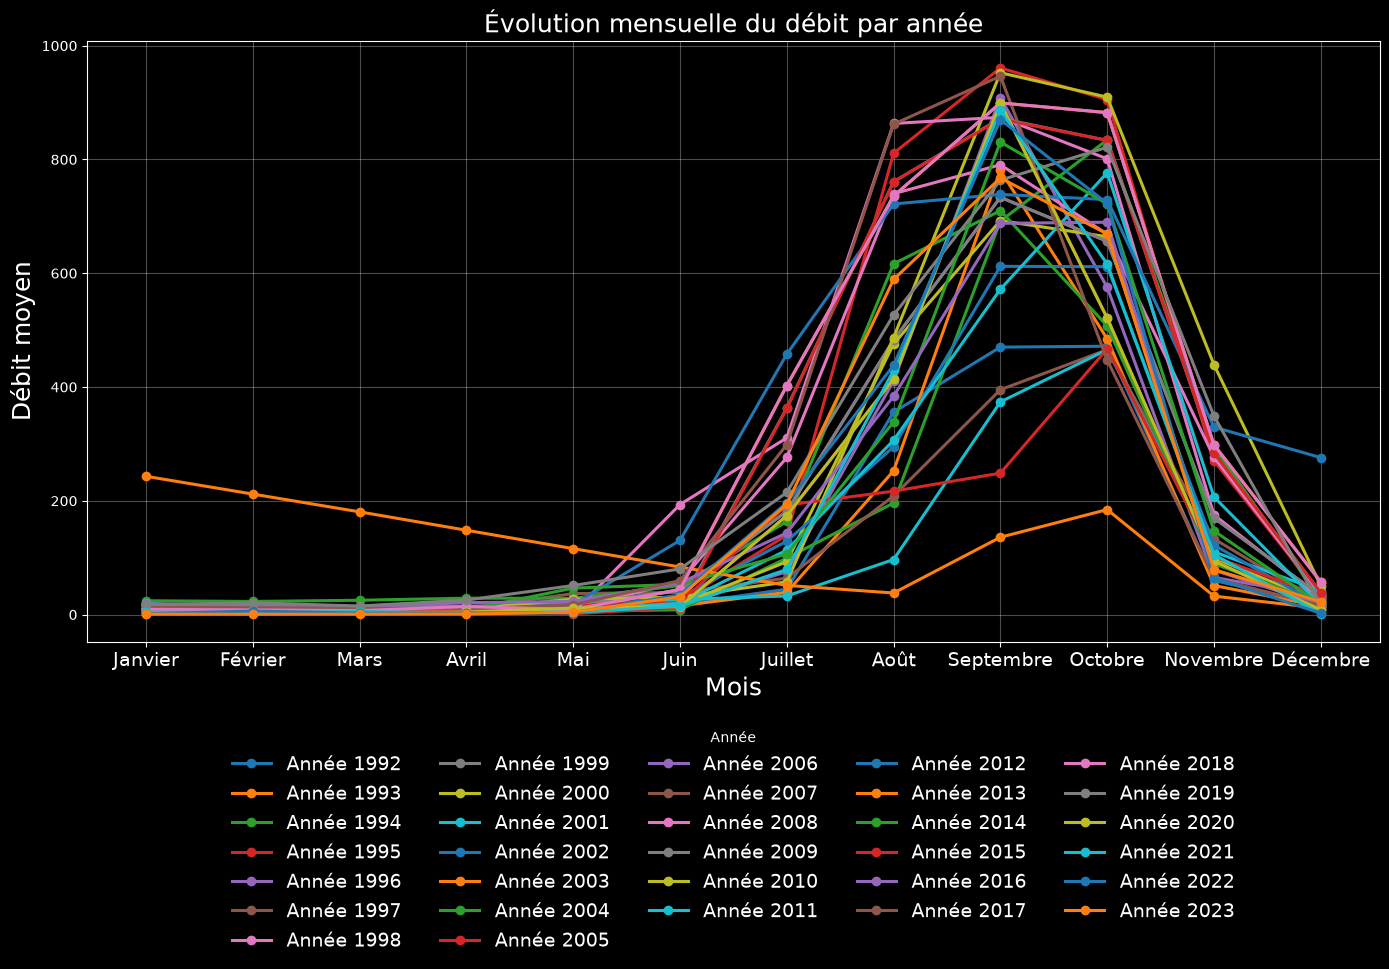

In [9]:
monthly = df.groupby(["Annee", "Mois"])["Valeur"].mean().reset_index()
monthly["Mois_label"] = monthly["Mois"].astype(int)

mois_nom = ["Janvier", "Février", "Mars", "Avril", "Mai", "Juin",
            "Juillet", "Août", "Septembre", "Octobre", "Novembre", "Décembre"]

plt.subplots(2,1,figsize=(14, 10))
colors = plt.cm.tab10.colors
for i, (annee, grp) in enumerate(monthly.groupby("Annee")):
    plt.plot(
        grp["Mois_label"],
        grp["Valeur"],
        marker="o",
        linewidth=2.2,
        markersize=6,
        color=colors[i % len(colors)],
        label=f"Année {annee}",axes=axes[0]
    )
    plt.plot(
            grp["Mois_label"],
            grp["Pluie"],
            marker="o",
            linewidth=2.2,
            markersize=6,
            color=colors[i % len(colors)],
            label=f"Année {annee}",axes=axes[1]
        )

plt.xticks(range(1, 13), mois_nom, fontsize=14)
plt.xlabel("Mois", fontsize=18)
plt.ylabel("Débit moyen", fontsize=18)
axes[0]._set_title("Évolution mensuelle du débit par année", fontsize=18)
plt.legend(title="Année", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=5, frameon=False, fontsize=14)
plt.grid(True, alpha=0.3)
plt.tight_layout();

## 6. Autocorrélation du débit

L'analyse de la fonction d'autocorrélation du débit journalier révèle une forte dépendance temporelle. Les autocorrélations sont élevées pour les premiers retards et décroissent progressivement, tout en restant significatives jusqu'à 30 jours. Cette décroissance lente indique que les observations de débit successives sont fortement dépendantes à court terme et présentent une mémoire temporelle importante. Les modèles classiques comme les modèles linéaires et les modèles d'arbres peuvent donc être envisagés, à condition de créer au préalable des caractéristiques qui captent cette dépendance.

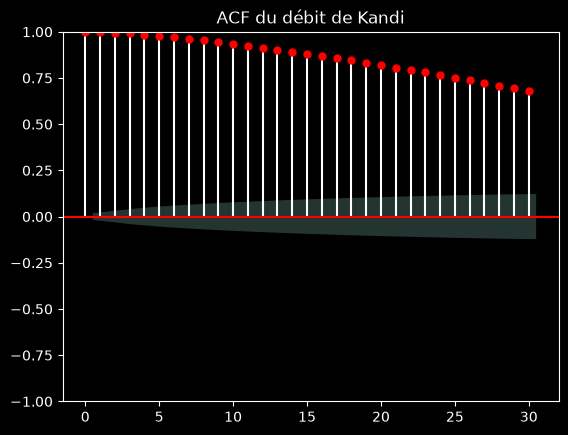

In [10]:
fig,axes=plt.subplots(1,2)

plot_acf(data["Valeur"],lags=30,title="ACF du débit de Kandi",color="red",ax=axes[0])
plot_acf(data["Pluie"],lags=30,title="ACF du Pluie de Kandi",color="red",ax=axes[1])

plt.show()

## 7. Test de stationnarité (ADF)

Étant donné que la p-value est négligeable, on conclut que les données de débit sont stationnaires.

In [11]:
resultats = adfuller(data["Valeur"])

print("Test ADF")
print("ADF statistic :", resultats[0])
print("p-value :", resultats[1])


Test ADF
ADF statistic : -11.739562899594537
p-value : 1.28333317686979e-21


## Conclusion

De tout ce qui précède, il paraît pertinent de tester les modèles *SARIMA*, *Prophet*, ainsi que des modèles linéaires et des arbres de décision si possible.